# Tutorial 2, Problem 1. 

## Isomerization of normal butane 

- Description: Program to calculate the volume of a PFR reactor for a reversible isomerization reaction 
- Author: Dr Carlos Avendano
- Last version:  October 2026

In [1]:
# Required Libraries
import numpy as np                     # Library for array manupulations
import matplotlib.pyplot as plt        # Array for plotting
from scipy.integrate import solve_ivp  # ODE solver (Runge-Kutta)

In [2]:
def pfr(vol,z,v_flow):

    '''
    Model of the adiabatic plug-flow reactor.

    State variables:
        z[0] = molar flow rate of A, kmol/h
        z[1] = molar flow rate of B, kmol/h
        z[2] = molar flow rate of inert I, kmol/h
        z[3] = temperature, K

    Returns:
        dFA/dV, dFB/dV, dFI/dV, dT/dV
    '''

    # Unwrap the molar flow rates and temperature from the input array
    FA = z[0]
    FB = z[1]
    FI = z[2]
    temp = z[3]

    # Constants 
    R_ideal = 8.314  # Ideal gas constant in J/(mol*K)
    Ea = 65.7e3      # Activation energy in J/mol
    deltaH = -6900   # Enthalpy change in J/mol
    CpA = 141        # Heat capacity of A in J/(mol*K)
    CpB = 141        # Heat capacity of B in J/(mol*K)
    CpI = 161        # Heat capacity of I in J/(mol*K)

    # Temperature-dependent rate constant
    k = k_constant(temp)

    # Temperature-dependent equilibrium constant
    KC = KC_constant(temp)

    # Concentrations of A and B in the reactor
    CA = FA/v_flow
    CB = FB/v_flow

    # Calculate the rate of reaction using the rate law
    rA = -k*(CA - CB/KC)

    # Molar balances
    dFA_dV = rA
    dFB_dV = -rA
    dFI_dV = 0

    # Adiabatic energy balance
    dT_dV = (rA*deltaH)/(CpA*FA + CpB*FB + CpI*FI)

    # Return the system of differential equations
    return [dFA_dV, dFB_dV, dFI_dV, dT_dV]


def k_constant(temp):
    '''
    Calculate the temperature-dependent rate constant.

    Parameters:
        temp (float): Temperature in K

    Returns:
        float: Temperature-dependent rate constant
    '''
    R_ideal = 8.314  # Ideal gas constant in J/(mol*K)
    Ea = 65.7e3      # Activation energy in J/mol

    return 31.1 * np.exp(-Ea/R_ideal*(1/temp - 1/360))


def KC_constant(temp):
    '''
    Calculate the temperature-dependent equilibrium constant.

    Parameters:
        temp (float): Temperature in K  

    Returns:
        float: Temperature-dependent equilibrium constant
    '''
    R_ideal = 8.314  # Ideal gas constant in J/(mol*K)
    deltaH = -6900   # Enthalpy change in J/mol

    return 3.03 * np.exp(-deltaH/R_ideal*(1/temp - 1/333.15))

## Solving the system of differential equations

In [3]:
# Initial conditions

# Initial molar flow rate of A
FA0 = 146.7  # kmol/h
# Initial molar flow rate of B
FB0 = 0      # kmol/h
# Initial molar flow rate of I
FI0 = 16.3   # mol/h
# Initial temperature
T0 = 330     # K

# Calculate the constant volumetric flow rate using the initial 
# molar flow rates and the intial concentration of A
CA0 = 9.3              # kmol/m^3
v_rate = FA0/CA0       # m^3/s

# Initial conditions for the molar flow rates and temperature
z0 = [FA0, FB0, FI0, T0]


# Define the volume range and number of steps for the simulation
vol_steps = 500
vol_span = (0, 5)
vol_array = np.linspace(vol_span[0], vol_span[1], vol_steps)

# Solve the system of ODEs using the Runge-Kutta method
solution = solve_ivp(pfr, 
                     t_span=vol_span, 
                     y0=z0, 
                     t_eval=vol_array, 
                     args=(v_rate,)
                     )

# Extract the results for easier access
vol = solution.t
FA = solution.y[0,:]
FB = solution.y[1,:]
FI = solution.y[2,:]
temp = solution.y[3,:]

# Computer different properties of the system based on the solution

# Total molar flow rate
F_tot = FA + FB + FI

# COnversion of n-butane
conversion = 1-FA/FA0


# Calculate temperature-dependent parameters
k = 31.1 * np.exp(-65.7e3/8.314 * (1/solution.y[3,:] - 1/360.0))

KC = 3.03 * np.exp(-(-6900.0)/8.314 * (1/solution.y[3,:] - 1/333.15))

# Equilibrium conversion
Xe = KC/(1.0 + KC)

# Concentrations
CA = solution.y[0,:]/v_rate
CB = solution.y[1,:]/v_rate

# Rate of disappearance of A
minus_rA = k * (CA - CB/KC)



## Tabulate the data to extract numbers if needed

In [4]:
print('    {0:12} {1:12} {2:14} {3:12} {4:12} {5:12}'.format('Volume','Conversion','F_A', 'F_B', 'F_I', 'T'))
for i in range(vol_steps):
    print('{0:12.6f} {1:12.6f} {2:12.6f} {3:12.6f} {4:12.6f} {5:12.6f}'.format(
        vol[i],
        conversion[i], 
        FA[i],
        FB[i],
        FI[i],
        temp[i],
        ))

    Volume       Conversion   F_A            F_B          F_I          T           
    0.000000     0.000000   146.700000     0.000000    16.300000   330.000000
    0.010020     0.002692   146.305062     0.394938    16.300000   330.116911
    0.020040     0.005398   145.908178     0.791822    16.300000   330.234397
    0.030060     0.008116   145.509337     1.190663    16.300000   330.352464
    0.040080     0.010848   145.108528     1.591472    16.300000   330.471112
    0.050100     0.013594   144.705740     1.994260    16.300000   330.590347
    0.060120     0.016353   144.300966     2.399034    16.300000   330.710169
    0.070140     0.019126   143.894198     2.805802    16.300000   330.830582
    0.080160     0.021913   143.485422     3.214578    16.300000   330.951589
    0.090180     0.024713   143.074626     3.625374    16.300000   331.073194
    0.100200     0.027527   142.661799     4.038201    16.300000   331.195400
    0.110220     0.030355   142.246928     4.453072    16.

In [11]:
''' Alternatively, you can use the following code to 
    print the results using the pandas library in a 
    more readable format:'''

import pandas as pd
# Create a DataFrame to store the results
results_df = pd.DataFrame({
    'Volume': vol,
    'Conversion': conversion,
    'F_A': FA,
    'F_B': FB,
    'F_I': FI,
    'Temperature': temp
})

# Uncomment the following two lines to display all rows 
# and columns in the DataFrame

# pd.set_option("display.max_rows", None)
# pd.set_option("display.max_columns", None)

print(results_df)



       Volume  Conversion         F_A         F_B   F_I  Temperature
0    0.000000    0.000000  146.700000    0.000000  16.3   330.000000
1    0.010020    0.002692  146.305062    0.394938  16.3   330.116911
2    0.020040    0.005398  145.908178    0.791822  16.3   330.234397
3    0.030060    0.008116  145.509337    1.190663  16.3   330.352464
4    0.040080    0.010848  145.108528    1.591472  16.3   330.471112
5    0.050100    0.013594  144.705740    1.994260  16.3   330.590347
6    0.060120    0.016353  144.300966    2.399034  16.3   330.710169
7    0.070140    0.019126  143.894198    2.805802  16.3   330.830582
8    0.080160    0.021913  143.485422    3.214578  16.3   330.951589
9    0.090180    0.024713  143.074626    3.625374  16.3   331.073194
10   0.100200    0.027527  142.661799    4.038201  16.3   331.195400
11   0.110220    0.030355  142.246928    4.453072  16.3   331.318212
12   0.120240    0.033197  141.830002    4.869998  16.3   331.441631
13   0.130261    0.036053  141.411

## Finding the volume of the reactor for the target conversion

There are several ways to determine the volumet required to achieve the target conversion.

For example, if you have calculated the solution using a sufficiently fine grid, you can simply inspect the results and identify the weight of catalyst corresponding to a conversion of 0.7.

Another approach is as follows:

* Define the target conversion as 0.7.

* Create a new array containing the absolute difference between each calculated conversion and the target conversion.

* Use numpy.argmin() to find the position where this difference is smallest. This identifies the calculated conversion that is closest to the target value.

* Use the same position in the volume array to obtain the corresponding volume of the reactor.

* Use the same position for any other properties

In [30]:
# Target conversion
x_target = 0.7

# Create array containing the absolute difference between conversion and target conversion
difference = np.abs(conversion - x_target)

# Find the position of the minimum
index_min = np.argmin(difference)

# Evalauate properties at the target conversion
volume_actual = solution.t[index_min]
x_actual = conversion[index_min]
FA_actual = solution.y[0,index_min]
FB_actual = solution.y[1,index_min]
FI_actual = solution.y[2,index_min]
T_actual = solution.y[3,index_min]
KC_actual = KC[index_min]



print('At the conversion  X={0:7.6f}, the properties are:'.format(x_actual))
print('      - volume = {0:7.6f}'.format(volume_actual))
print('      - F_A = {0:7.6f}'.format(FA_actual))
print('      - F_B = {0:7.6f}'.format(FB_actual))
print('      - F_I = {0:7.6f}'.format(FI_actual))
print('      - T   = {0:7.6f}'.format(T_actual))
print('      - KC  = {0:7.6f}'.format(KC_actual))


At the conversion  X=0.699906, the properties are:
      - volume = 2.484970
      - F_A = 44.023742
      - F_B = 102.676258
      - F_I = 16.300000
      - T   = 360.394533
      - KC  = 2.509895


## Plotting the results

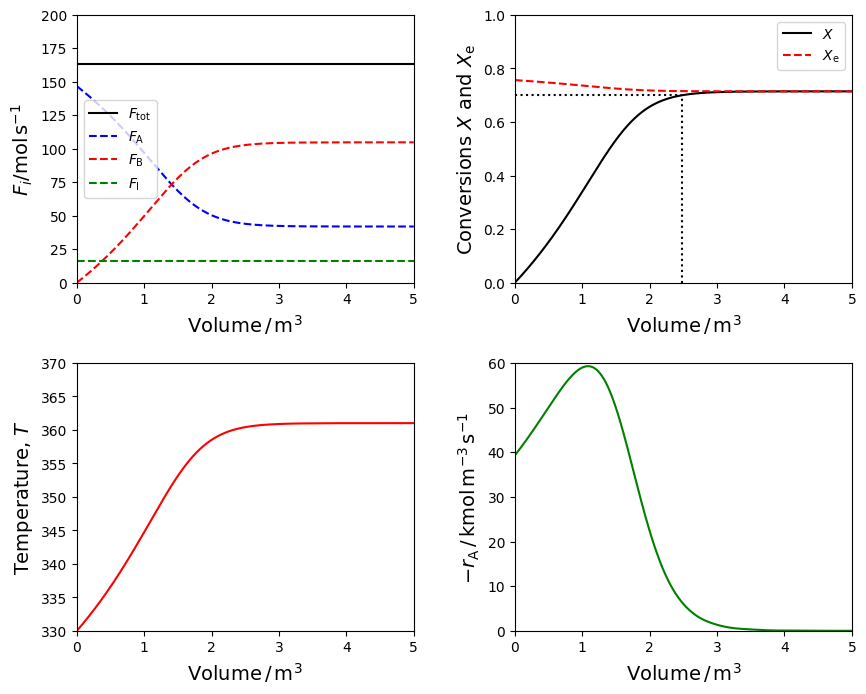

In [47]:
# Create a plot object. The size is in inches
fig=plt.figure(figsize=(10,8))

# Create 2X2 subplots in the figure. 
ax1 = fig.add_subplot(2, 2, 1)
ax2 = fig.add_subplot(2, 2, 2)
ax3 = fig.add_subplot(2, 2, 3)
ax4 = fig.add_subplot(2, 2, 4)

plt.subplots_adjust(wspace=0.3,hspace=0.3) # This adjust the spacing between plots

# Plot the molar flow rates
ax1.plot(solution.t,F_tot, '-k',label=r'$F_\mathrm{tot}$')
ax1.plot(solution.t,solution.y[0], '--b',label=r'$F_\mathrm{A}$')
ax1.plot(solution.t,solution.y[1], '--r',label=r'$F_\mathrm{B}$')
ax1.plot(solution.t,solution.y[2], '--g',label=r'$F_\mathrm{I}$')
ax1.set_xlabel(r'$\mathrm{Volume}\,/\,{\rm m^3}$',size=14)
ax1.set_ylabel(r'$F_i/\mathrm{mol\,s^{-1}}$',size=14)
ax1.set_xlim([0,5])
ax1.set_ylim([0,200])
ax1.legend()


# Plot conversion and target conversion
ax2.plot(solution.t,conversion,'-k',label=r'$X$')
ax2.plot(solution.t,Xe,'--r',label=r'$X_\mathrm{e}$')
ax2.plot([volume_actual,volume_actual],[0,x_target],':k')
ax2.plot([0,volume_actual],[x_target,x_target],':k')
ax2.set_xlabel(r'$\mathrm{Volume}\,/\,{\rm m^3}$',size=14)
ax2.set_ylabel(r'Conversions $X$ and $X_\mathrm{e}$',size=14)
ax2.set_xlim([0,5])
ax2.set_ylim([0,1])
ax2.legend()

# Plot the temperature
ax3.plot(solution.t,solution.y[3],'-r',label=r'$T$')
ax3.set_xlabel(r'$\mathrm{Volume}\,/\,{\rm m^3}$',size=14)
ax3.set_ylabel(r'Temperature, $T$',size=14)
ax3.set_xlim([0,5])
ax3.set_ylim([330,370])

# Rate of disappearance of A
ax4.plot(solution.t,minus_rA,'-g',label=r'$-r_\mathrm{A}$')
ax4.set_xlabel(r'$\mathrm{Volume}\,/\,{\rm m^3}$',size=14)
ax4.set_ylabel(r'$-r_\mathrm{A}\,/\,{\rm kmol\,m^{-3}\,s^{-1}}$',size=14)
ax4.set_xlim([0,5])
ax4.set_ylim([0,60])


# Save figure 
plt.savefig("adiabatic_butane.pdf", bbox_inches='tight')
# Display figure
plt.show()